In [60]:
import numpy as np
import csv
import matplotlib.pyplot as plt

#REYNOLDS NUMBER CALCULATION-----------------------------------------------------------------------------------------------------------------------------------------------------------

rho_cruise = 0.3796 #ISA
V_cruise = 0.85 * 296.5 #ISA
mu_cruise = 1.3885e-5 #NASA 
c_ref = 8.174 #VSP


Re = (rho_cruise * V_cruise * c_ref) / mu_cruise
print("Reynolds number at cruise conditions:", Re)

#-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

data = {}
read_polar = False

#IMPORT DATA FROM AERO.CSV ---------------------------------------------------------------------------------------------------------------------------------------------------------------

with open('Data/Aero_Angle_0_Full_payload_Full_fuel.csv', 'r', encoding="utf-8-sig") as file:
    reader = csv.reader(file)


    for row in reader: 


        if row[0] == 'Results_Name' and row[1] == 'VSPAERO_Polar':
            read_polar = True
            continue

        if read_polar and row[0] == 'Results_Name':
            break

        if read_polar and not row[0].startswith('Results_Name'):
            data[row[0]] = [
                            float(value) if value.strip() else np.nan
                            for value in row[1:]
                            ]

print(data)



#-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

Reynolds number at cruise conditions: 56319472.240547344
{'Results_Timestamp': [1792158035.0], 'Results_Date': [10.0, 16.0, 2026.0], 'Results_Time': [15.0, 40.0, 35.0], 'Alpha': [-5.0, -4.0, -3.0, -2.0, -1.0, 0.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0], 'Beta': [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0], 'CDi': [0.010909115662, 0.006864061207, 0.003766083558, 0.001629098291, 0.000462840024, 0.000274315763, 0.001068725877, 0.002849654593, 0.005616945423, 0.009368180179, 0.014099542526, 0.019802955932, 0.026455109682, 0.034062180519, 0.042717872649, 0.052379080741], 'CDiw': [0.012798602525, 0.008031214833, 0.004388276861, 0.001884193382, 0.000534401717, 0.000350593812, 0.001343089012, 0.003519622841, 0.006885351541, 0.011441579581, 0.017193552527, 0.02413802954, 0.032272024733, 0.041608740229, 0.052163950078, 0.06386084282], 'CDo': [0.006825351358, 0.006193961363, 0.005710228007, 0.00537536351, 0.005190371067, 0.00515566121, 0.00527123904

[0.85851381 0.84871721 0.82752666 0.76417917 0.46790574 0.12530948
 0.6541515  0.77533643 0.81214927 0.82717266 0.83438352 0.8380851
 0.84035583 0.84132846 0.84011927 0.83811983]


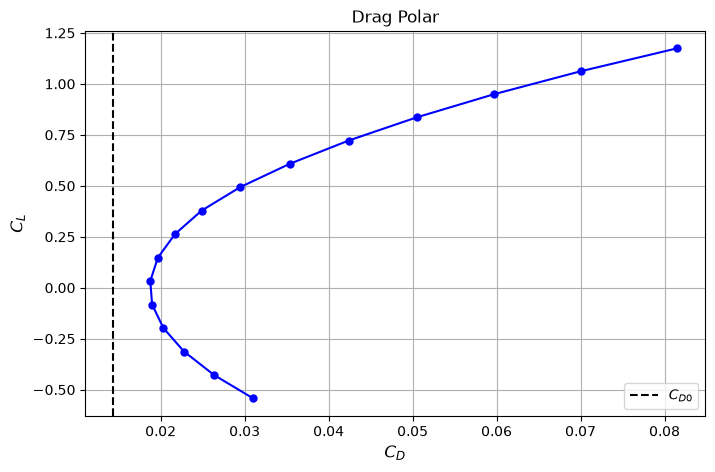

In [62]:
#DRAG POLAR PLOT ------------------------------------------------------------------------------------------------------------------------------------------------------------------------

C_L = np.array(data['CLtot'], dtype=np.float64)
# print(C_L)
# print(C_L**2)

C_D0 = 0.01438

C_Di = np.array(data['CDi'])
# print(data['CDi'])

C_Dvisc = 0.38 * C_D0 * C_L**2

C_Dwave = []

for cl in C_L: 
    M_cruise = 0.85
    from scipy.interpolate import PchipInterpolator, CubicHermiteSpline
    ### your inputs here #############
    A_max = 88 #86 max cross sectional area 
    lam = 35 # leading edge sweep angle in degrees 
    l = 82.53 - (25-12)  # length of the fuselage where the curvature changes (use the cross-sectional area plot in VSP)
    S_ref = 506.95 #reference area
    Cl = cl #cruise lifT coef
    MddL0 = 0.87 # (0.6 thickness: 0.87) 0.855 readout from fig 12.29 in Raymer 0.855
    Mddfus = 0.82 #0.7865 before longation of nose readout from fig 12.31 in Raymer,  (2 L_n / d = 3.09) MEAN AREA USING 
    LF = 0.967 #(0.6 thickness: 0.967)   0.95 readout from fig 12.30 in Raymer 0.951
    ####################################
    Ewd = 1.8
    M_super= np.linspace(1.2, 2, 20)
    d_q_sh = 9*np.pi/2*(A_max/l)**2
    d_q_s = Ewd*(1-0.386*(M_super-1.2)**0.57*(1-(np.pi*lam**0.77)/100))*d_q_sh
    Cd_w_s = d_q_s/S_ref
    Cd_w_12 = d_q_s[0]/S_ref
    Cd_w_105 = Cd_w_12
    M_dd = min(MddL0*LF-0.05*Cl,Mddfus)
    M_cr = M_dd - 0.08
    M = [M_cr, M_dd,1.0, 1.05]
    M_1 = np.concatenate((M,M_super), axis=0)
    Cd_w = [0,0.002, (Cd_w_105)/2, Cd_w_105]
    Cd_1 = np.concatenate((Cd_w,Cd_w_s),axis=0)
    M_new = np.linspace(M_cr,2,100)
    # Cubic Hermite interpolation through the points: PCHIP slopes (no overshoot, no negative drag),
    # except at M=1.05 where the slope keeps the M=1.0-1.05 rise, giving the drag peak near M~1.1
    slopes = PchipInterpolator(M_1, Cd_1).derivative()(M_1)
    slopes[3] = 0.5*(Cd_1[3] - Cd_1[2]) / (M_1[3] - M_1[2])
    cd_smooth = CubicHermiteSpline(M_1, Cd_1, slopes)

    if M_cruise <= M_cr:
        C_D_wave_085 = 0.0  
    else:
        C_D_wave_085 = float(cd_smooth(M_cruise))
        C_Dwave.append(C_D_wave_085)

C_Dwave = np.array(C_Dwave, dtype=np.float64)

C_D = C_D0 + C_Di + C_Dvisc + C_Dwave
# print(C_D)

e = C_L**2 / (np.pi * 10 * C_Di)
print(e)

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(C_D, C_L, color='blue', marker='o', markersize=5, linestyle='-')

#Mark C_D0 with vertical black dashed line
ax.axvline(x=C_D0, color='black', linestyle='--', label='$C_{D0}$')

ax.set_xlabel('$C_D$', fontsize=12)
ax.set_ylabel('$C_L$', fontsize=12)
ax.set_title('Drag Polar')
ax.legend()
ax.grid(True)

#----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

Text(0, 0.5, '$C_L$')

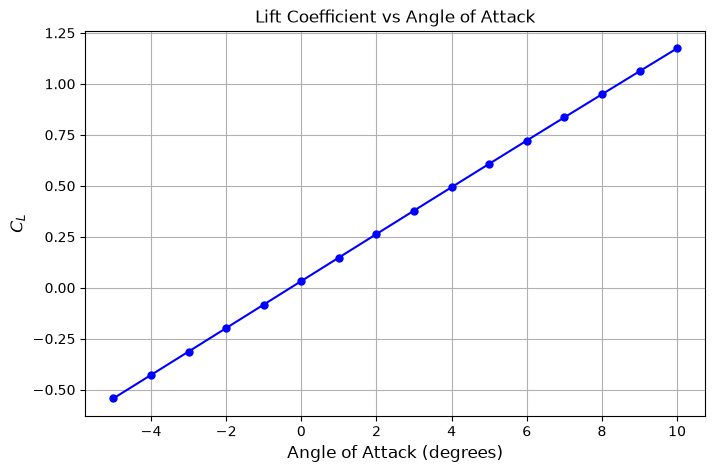

In [63]:
#LIFT COEFFICIENT vs ALPHA ------------------------------------------------------------------------------------------------------------------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(data['Alpha'], data['CLtot'], color='blue', marker='o', markersize=5, linestyle='-')  
ax.grid()
ax.set_title('Lift Coefficient vs Angle of Attack')
ax.set_xlabel('Angle of Attack (degrees)', fontsize=12)
ax.set_ylabel('$C_L$', fontsize=12)


#----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

Text(0, 0.5, '$C_D$')

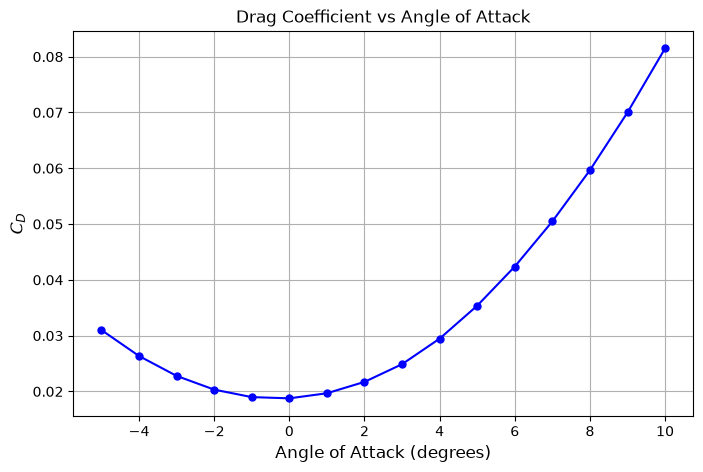

In [86]:
#DRAG COEFFICIENT ALPHA ------------------------------------------------------------------------------------------------------------------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(data['Alpha'], C_D, color='blue', marker='o', markersize=5, linestyle='-')
ax.grid()
ax.set_title('Drag Coefficient vs Angle of Attack')
ax.set_xlabel('Angle of Attack (degrees)', fontsize=12)
ax.set_ylabel('$C_D$', fontsize=12)

#----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

Text(0, 0.5, '$C_{D_i}$')

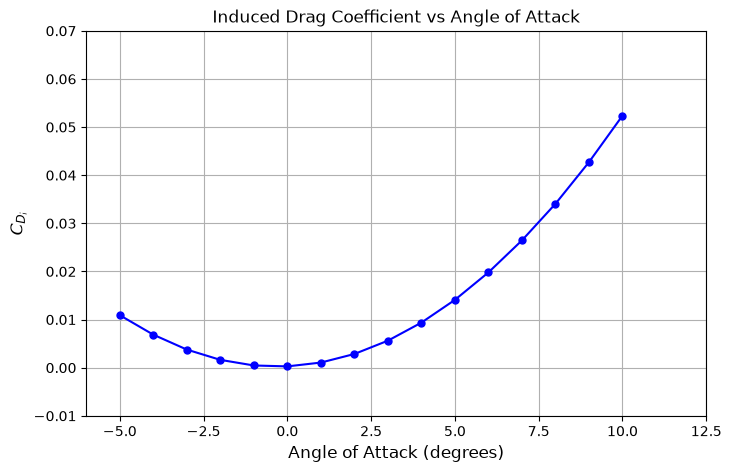

In [ ]:
#INDUCED DRAG COEFFICIENT vs ALPHA ------------------------------------------------------------------------------------------------------------------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(data['Alpha'], C_Di, color='blue', marker='o', markersize=5, linestyle='-')
ax.grid()
ax.set_title('Induced Drag Coefficient vs Angle of Attack')
ax.set_xlabel('Angle of Attack (degrees)', fontsize=12)
ax.set_ylabel('$C_{D_i}$', fontsize=12)

#----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

C:\Users\cevin\AppData\Local\Temp\ipykernel_32540\3328571409.py:9: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


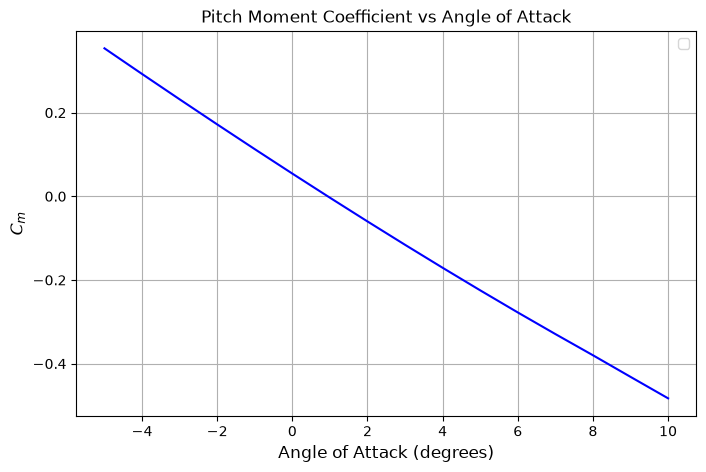

In [66]:
#PITCH MOMENT COEFFICIENT vs ALPHA ------------------------------------------------------------------------------------------------------------------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(data['Alpha'], data['CMytot'], color='blue', markersize=5, linestyle='-')
ax.grid()
ax.set_title('Pitch Moment Coefficient vs Angle of Attack')
ax.set_xlabel('Angle of Attack (degrees)', fontsize=12)
ax.set_ylabel('$C_m$', fontsize=12)
ax.legend()

#----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

Text(0, 0.5, '$L/D$')

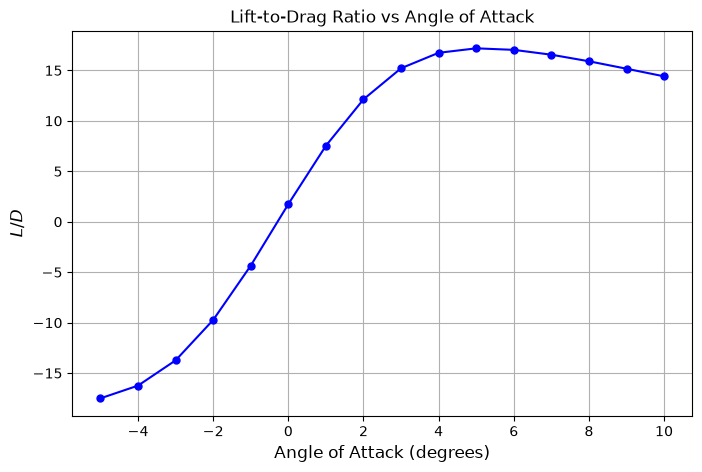

In [68]:
#L/D RATIO vs ALPHA ------------------------------------------------------------------------------------------------------------------------------------------------------------------------

LD = C_L / C_D

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(data['Alpha'], LD, color='blue', marker='o', markersize=5, linestyle='-')
ax.grid()
ax.set_title('Lift-to-Drag Ratio vs Angle of Attack')
ax.set_xlabel('Angle of Attack (degrees)', fontsize=12)
ax.set_ylabel('$L/D$', fontsize=12)


#----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

{'Results_Timestamp': [1792158600.0], 'Results_Date': [10.0, 16.0, 2026.0], 'Results_Time': [15.0, 50.0, 0.0], 'Alpha': [-5.0, -4.0, -3.0, -2.0, -1.0, 0.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0], 'Beta': [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0], 'CDi': [0.029185179742, 0.022996714193, 0.017743731128, 0.01345843673, 0.010165160559, 0.007944780084, 0.006752114334, 0.006606590337, 0.007547826839, 0.009584341251, 0.012727740261, 0.016985806757, 0.022363483326, 0.028876079331, 0.03655903501, 0.045588379202], 'CDiw': [0.029924034864, 0.022202471303, 0.015854031859, 0.0109017343, 0.007309728551, 0.005131303126, 0.004296631157, 0.004793969397, 0.006634936638, 0.009802611347, 0.014290548411, 0.020093619217, 0.027212989329, 0.035665300432, 0.045417059881, 0.056583439749], 'CDo': [0.007450470438, 0.006735285833, 0.006171241488, 0.005760803631, 0.005502748263, 0.005400368542, 0.005451993993, 0.005657113351, 0.006015666271, 0.006526141556, 0.00718

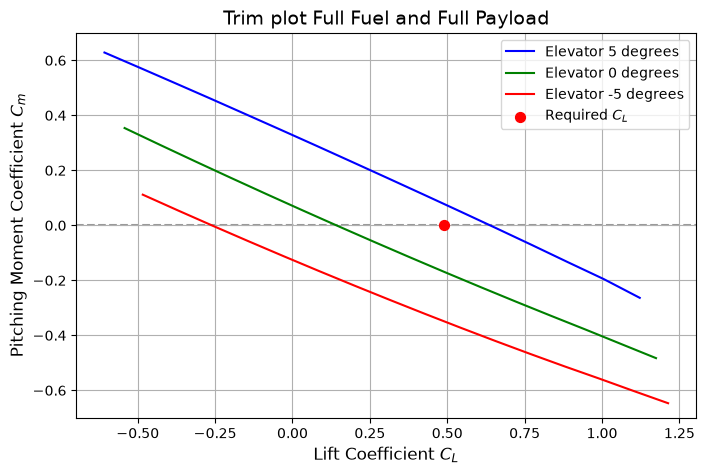

In [97]:
data5 = {}
read_polar = False

#IMPORT DATA FROM AERO.CSV ---------------------------------------------------------------------------------------------------------------------------------------------------------------

with open('Data/Aero_Angle_5_Full_payload_Full_fuel.csv', 'r', encoding="utf-8-sig") as file:
    reader = csv.reader(file)


    for row in reader: 


        if row[0] == 'Results_Name' and row[1] == 'VSPAERO_Polar':
            read_polar = True
            continue

        if read_polar and row[0] == 'Results_Name':
            break

        if read_polar and not row[0].startswith('Results_Name'):
            data5[row[0]] = [
                            float(value) if value.strip() else np.nan
                            for value in row[1:]
                            ]

print(data5)



datamin5 = {}
read_polar = False

#IMPORT DATA FROM AERO.CSV ---------------------------------------------------------------------------------------------------------------------------------------------------------------

with open('Data/Aero_Angle_-5_Full_payload_Full_fuel.csv', 'r', encoding="utf-8-sig") as file:
    reader = csv.reader(file)


    for row in reader: 


        if row[0] == 'Results_Name' and row[1] == 'VSPAERO_Polar':
            read_polar = True
            continue

        if read_polar and row[0] == 'Results_Name':
            break

        if read_polar and not row[0].startswith('Results_Name'):
            datamin5[row[0]] = [
                            float(value) if value.strip() else np.nan
                            for value in row[1:]
                            ]

            
print(datamin5)

# TRIM PLOT FULL FUEL FULL PAYLOAD ------------------------------------------------------------------------------------------------------------------------------------------------------------------------

m_fullfuelfullpayload = 303785.80 #ADD LANDING GEAR AS WELL!!!
S_ref = 506.95
C_L_fullfuelfullpayload = m_fullfuelfullpayload * 9.82 / (0.5 * rho_cruise * V_cruise**2 * S_ref)
print("Trim point for full fuel and full payload: C_L =", C_L_fullfuelfullpayload)

fig, ax = plt.subplots(figsize=(8, 5))
ax.set_ylim([-0.7, 0.7])
ax.set_title('Trim plot Full Fuel and Full Payload', fontsize=14)
ax.plot(data5['CLtot'], data5['CMytot'], color='blue', markersize=5, linestyle='-', label = 'Elevator 5 degrees')
ax.plot(data['CLtot'], data['CMytot'], color='green', markersize=5, linestyle='-', label = 'Elevator 0 degrees')
ax.plot(datamin5['CLtot'], datamin5['CMytot'], color='red', markersize=5, linestyle='-', label = 'Elevator -5 degrees')
ax.scatter(C_L_fullfuelfullpayload, 0, color='red', marker='o', s=50, label = 'Required $C_L$', zorder=5)
ax.set_xlabel('Lift Coefficient $C_L$', fontsize=12)
ax.set_ylabel('Pitching Moment Coefficient $C_m$', fontsize=12)
ax.legend()
ax.grid()
#Make grid line at C_m = 0 thicker
ax.axhline(y=0, color='black', linestyle='--', linewidth=1.5, zorder=0, alpha=0.4)



{'Results_Timestamp': [1792159565.0], 'Results_Date': [10.0, 16.0, 2026.0], 'Results_Time': [16.0, 6.0, 5.0], 'Alpha': [-5.0, -4.0, -3.0, -2.0, -1.0, 0.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0], 'Beta': [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0], 'CDi': [0.010909115662, 0.006864061207, 0.003766083558, 0.001629098291, 0.000462840024, 0.000274315763, 0.001068725877, 0.002849654593, 0.005616945423, 0.009368180179, 0.014099542526, 0.019802955932, 0.026455109682, 0.034062180519, 0.042717872649, 0.052379080741], 'CDiw': [0.012798602525, 0.008031214833, 0.004388276861, 0.001884193382, 0.000534401717, 0.000350593812, 0.001343089012, 0.003519622841, 0.006885351541, 0.011441579581, 0.017193552527, 0.02413802954, 0.032272024733, 0.041608740229, 0.052163950078, 0.06386084282], 'CDo': [0.006825351358, 0.006193961363, 0.005710228007, 0.00537536351, 0.005190371067, 0.00515566121, 0.005271239047, 0.005536646499, 0.005951002551, 0.006512724957, 0.007220

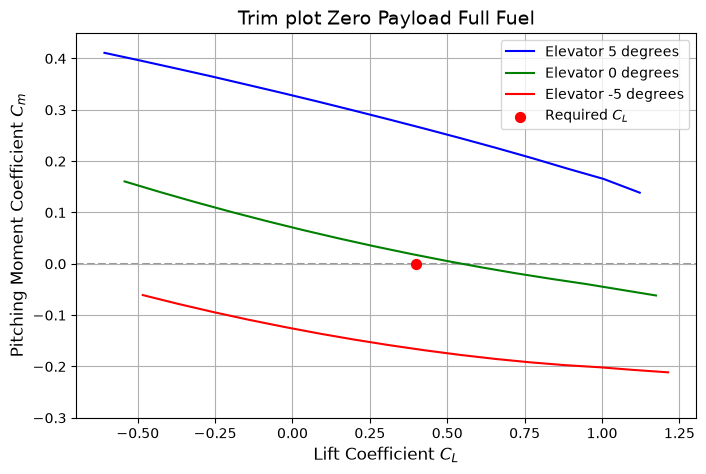

In [98]:

#IMPORT DATA FROM AERO.CSV ---------------------------------------------------------------------------------------------------------------------------------------------------------------


data0 = {}
read_polar = False

with open('Data/Aero_Angle_0_Zero_payload_Full_fuel.csv', 'r', encoding="utf-8-sig") as file:
    reader = csv.reader(file)


    for row in reader: 


        if row[0] == 'Results_Name' and row[1] == 'VSPAERO_Polar':
            read_polar = True
            continue

        if read_polar and row[0] == 'Results_Name':
            break

        if read_polar and not row[0].startswith('Results_Name'):
            data0[row[0]] = [
                            float(value) if value.strip() else np.nan
                            for value in row[1:]
                            ]

print(data0)





data5 = {}
read_polar = False

with open('Data/Aero_Angle_5_Zero_payload_Full_fuel.csv', 'r', encoding="utf-8-sig") as file:
    reader = csv.reader(file)


    for row in reader: 


        if row[0] == 'Results_Name' and row[1] == 'VSPAERO_Polar':
            read_polar = True
            continue

        if read_polar and row[0] == 'Results_Name':
            break

        if read_polar and not row[0].startswith('Results_Name'):
            data5[row[0]] = [
                            float(value) if value.strip() else np.nan
                            for value in row[1:]
                            ]

print(data5)



datamin5 = {}
read_polar = False


with open('Data/Aero_Angle_-5_Zero_payload_Full_fuel.csv', 'r', encoding="utf-8-sig") as file:
    reader = csv.reader(file)
    

    for row in reader: 


        if row[0] == 'Results_Name' and row[1] == 'VSPAERO_Polar':
            read_polar = True
            continue

        if read_polar and row[0] == 'Results_Name':
            break

        if read_polar and not row[0].startswith('Results_Name'):
            datamin5[row[0]] = [
                            float(value) if value.strip() else np.nan
                            for value in row[1:]
                            ]

            
print(datamin5)

# TRIM PLOT ZERO PAYLOAD FULL FUEL------------------------------------------------------------------------------------------------------------------------------------------------------------------------

m_zeropayloadfullfuel = 248735.80 
S_ref = 506.95
C_L_zeropayloadfullfuel = m_zeropayloadfullfuel * 9.82 / (0.5 * rho_cruise * V_cruise**2 * S_ref)
print("Trim point for zero payload and full fuel: C_L =", C_L_zeropayloadfullfuel)

fig, ax = plt.subplots(figsize=(8, 5))
ax.set_ylim([-0.3, 0.45])
ax.set_title('Trim plot Zero Payload Full Fuel', fontsize=14)
ax.plot(data5['CLtot'], data5['CMytot'], color='blue', markersize=5, linestyle='-', label = 'Elevator 5 degrees')
ax.plot(data0['CLtot'], data0['CMytot'], color='green', markersize=5, linestyle='-', label = 'Elevator 0 degrees')
ax.plot(datamin5['CLtot'], datamin5['CMytot'], color='red', markersize=5, linestyle='-', label = 'Elevator -5 degrees')
ax.scatter(C_L_zeropayloadfullfuel, 0, color='red', marker='o', s=50, label = 'Required $C_L$', zorder=5)
ax.set_xlabel('Lift Coefficient $C_L$', fontsize=12)
ax.set_ylabel('Pitching Moment Coefficient $C_m$', fontsize=12)
ax.legend()
ax.grid()
#Make grid line at C_m = 0 thicker
ax.axhline(y=0, color='black', linestyle='--', linewidth=1.5, zorder=0, alpha=0.4)



{'Results_Timestamp': [1792161283.0], 'Results_Date': [10.0, 16.0, 2026.0], 'Results_Time': [16.0, 34.0, 43.0], 'Alpha': [-5.0, -4.0, -3.0, -2.0, -1.0, 0.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0], 'Beta': [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0], 'CDi': [0.010909115662, 0.006864061207, 0.003766083558, 0.001629098291, 0.000462840024, 0.000274315763, 0.001068725877, 0.002849654593, 0.005616945423, 0.009368180179, 0.014099542526, 0.019802955932, 0.026455109682, 0.034062180519, 0.042717872649, 0.052379080741], 'CDiw': [0.012798602525, 0.008031214833, 0.004388276861, 0.001884193382, 0.000534401717, 0.000350593812, 0.001343089012, 0.003519622841, 0.006885351541, 0.011441579581, 0.017193552527, 0.02413802954, 0.032272024733, 0.041608740229, 0.052163950078, 0.06386084282], 'CDo': [0.006825351358, 0.006193961363, 0.005710228007, 0.00537536351, 0.005190371067, 0.00515566121, 0.005271239047, 0.005536646499, 0.005951002551, 0.006512724957, 0.0072

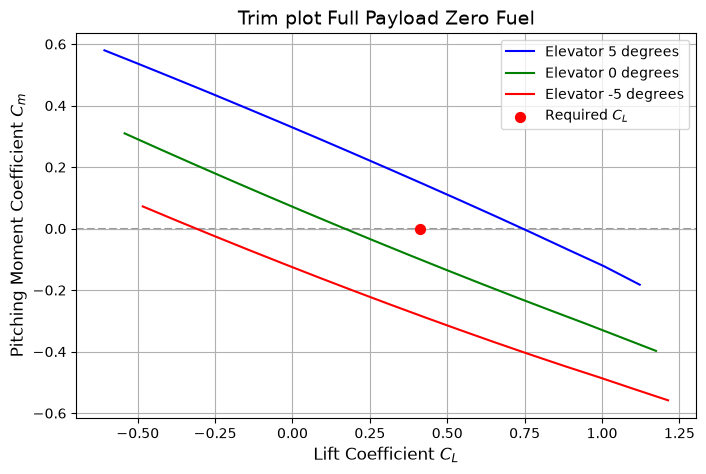

In [100]:

#IMPORT DATA FROM AERO.CSV ---------------------------------------------------------------------------------------------------------------------------------------------------------------


data0 = {}
read_polar = False

with open('Data/Aero_Angle_0_Full_payload_Zero_fuel.csv', 'r', encoding="utf-8-sig") as file:
    reader = csv.reader(file)


    for row in reader: 


        if row[0] == 'Results_Name' and row[1] == 'VSPAERO_Polar':
            read_polar = True
            continue

        if read_polar and row[0] == 'Results_Name':
            break

        if read_polar and not row[0].startswith('Results_Name'):
            data0[row[0]] = [
                            float(value) if value.strip() else np.nan
                            for value in row[1:]
                            ]

print(data0)





data5 = {}
read_polar = False

with open('Data/Aero_Angle_5_Full_payload_Zero_fuel.csv', 'r', encoding="utf-8-sig") as file:
    reader = csv.reader(file)


    for row in reader: 


        if row[0] == 'Results_Name' and row[1] == 'VSPAERO_Polar':
            read_polar = True
            continue

        if read_polar and row[0] == 'Results_Name':
            break

        if read_polar and not row[0].startswith('Results_Name'):
            data5[row[0]] = [
                            float(value) if value.strip() else np.nan
                            for value in row[1:]
                            ]

print(data5)



datamin5 = {}
read_polar = False



with open('Data/Aero_Angle_-5_Full_payload_Zero_fuel.csv', 'r', encoding="utf-8-sig") as file:
    reader = csv.reader(file)
    

    for row in reader: 


        if row[0] == 'Results_Name' and row[1] == 'VSPAERO_Polar':
            read_polar = True
            continue

        if read_polar and row[0] == 'Results_Name':
            break

        if read_polar and not row[0].startswith('Results_Name'):
            datamin5[row[0]] = [
                            float(value) if value.strip() else np.nan
                            for value in row[1:]
                            ]

            
print(datamin5)

# TRIM PLOT ZERO PAYLOAD FULL FUEL------------------------------------------------------------------------------------------------------------------------------------------------------------------------

m_fullpayloadzerofuel = 255511.87
S_ref = 506.95
C_L_fullpayloadzerofuel = m_fullpayloadzerofuel * 9.82 / (0.5 * rho_cruise * V_cruise**2 * S_ref)
print("Trim point for full payload and zero fuel: C_L =", C_L_fullpayloadzerofuel)

fig, ax = plt.subplots(figsize=(8, 5))
ax.set_title('Trim plot Full Payload Zero Fuel', fontsize=14)
ax.plot(data5['CLtot'], data5['CMytot'], color='blue', markersize=5, linestyle='-', label = 'Elevator 5 degrees')
ax.plot(data0['CLtot'], data0['CMytot'], color='green', markersize=5, linestyle='-', label = 'Elevator 0 degrees')
ax.plot(datamin5['CLtot'], datamin5['CMytot'], color='red', markersize=5, linestyle='-', label = 'Elevator -5 degrees')
ax.scatter(C_L_fullpayloadzerofuel, 0, color='red', marker='o', s=50, label = 'Required $C_L$', zorder=5)
ax.set_xlabel('Lift Coefficient $C_L$', fontsize=12)
ax.set_ylabel('Pitching Moment Coefficient $C_m$', fontsize=12)
ax.legend()
ax.grid()
#Make grid line at C_m = 0 thicker
ax.axhline(y=0, color='black', linestyle='--', linewidth=1.5, zorder=0, alpha=0.4)

